# MULTI-AGENTIC GRAPHRAG SYSTEM with NEO4J and CREWAI
**Members:**

- Thi Kim Khanh Le

- Bolun Du

- Linxiao Jin

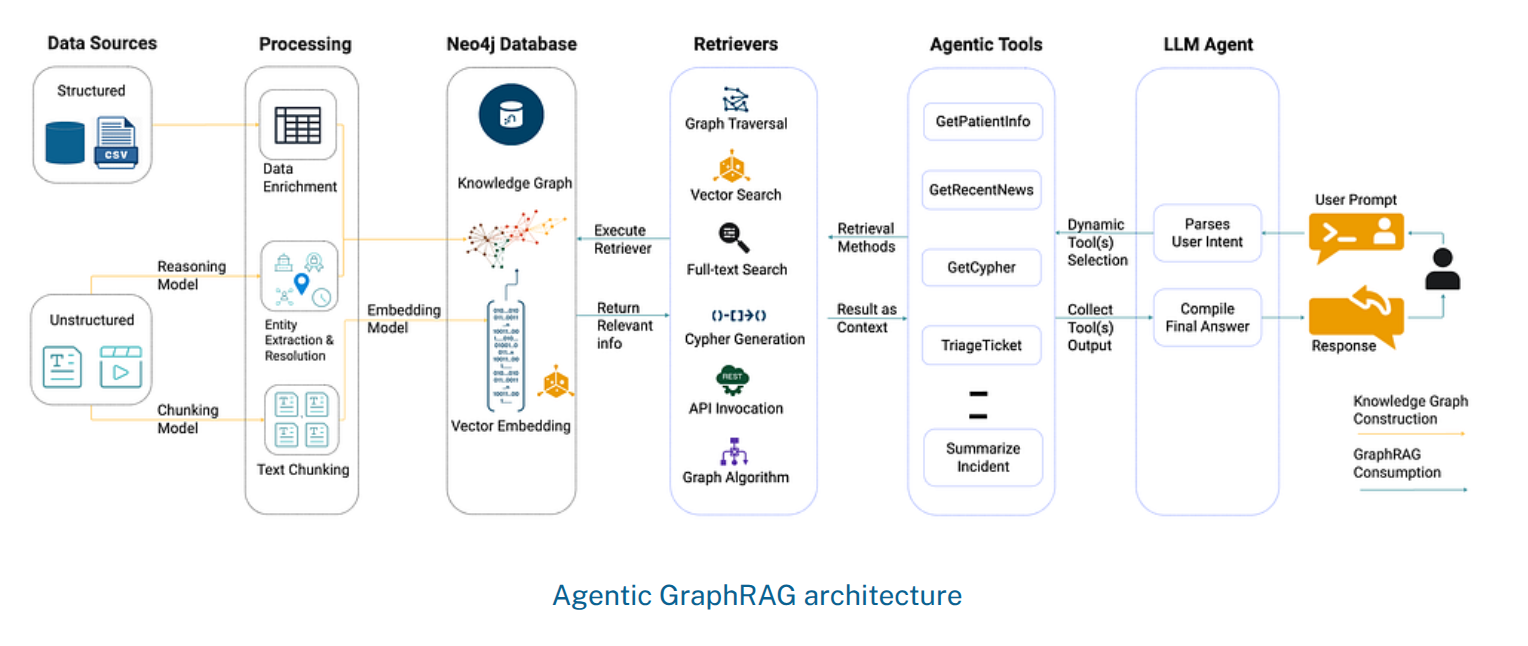
*(Source: Neo4j)*


## Overview

This project implements a **Multi-Agentic GraphRAG (Graph Retrieval-Augmented Generation)** system that combines knowledge graphs with intelligent multi-agent orchestration. The system leverages Neo4j Aura for graph storage, CrewAI for multi-agent orchestration, and Google's Vertex AI for both embeddings and language model capabilities.

## From Knowledge Graph to Agentic System

After building our knowledge graph on **Neo4j Aura**, we now connect it with our development environment (**Google Colab**) to enable intelligent querying through a multi-agent system.

A critical design decision is **model consistency**: since we used Vertex AI's **text-embedding-005** to create embeddings during knowledge graph construction, our multi-agent LLM system uses the same embedding model to ensure vector compatibility and accurate semantic search results. All agents are powered by **Gemini 2.5 Flash** for consistent reasoning capabilities.

## Agentic Architecture Inspiration

Our multi-agent system is built based on the standard GraphRAG architecture pattern, which includes:

- **Data Sources**: Structured and unstructured data ingestion
- **Processing**: Entity extraction, text chunking, and embedding generation
- **Neo4j Database**: Knowledge graph with nodes, relationships, and vector embeddings
- **Retrievers**: Multiple strategies including graph traversal, vector search, and Cypher generation
- **Agentic Tools**: Specialized tools for different query types
- **LLM Agent**: Orchestration layer that parses intent, selects tools, and generates responses

Following this architecture, we implemented **6 specialized agents** that collaborate to answer user questions.

## Our Multi-Agent Implementation

### Agent Workflow:
```
User Question
     ↓
[1] Schema Expert → Analyzes query & recommends approach
     ↓
[2] Semantic Search Specialist → Finds similar entities
     ↓
[3] NL Query Expert → Converts question to Cypher
     ↓
[4] Embedding Fallback Searcher → Searches text content
     ↓
[5] Results Synthesizer → Combines all findings
     ↓
[6] Answer Generator → Creates natural language response
     ↓
Final Answer
```

### Agent Details:

| Agent | Role | Tools |
|-------|------|-------|
| **Schema Expert** | Determines optimal query strategy | Cypher Templates, Database Diagnostics |
| **Semantic Search Specialist** | Finds conceptually similar entities | Vector Search, Diagnostics |
| **NL Query Expert** | Converts natural language to Cypher | Text-to-Cypher Generator |
| **Embedding Fallback Searcher** | Searches embedded text content | Embedding Retriever, Diagnostics |
| **Results Synthesizer** | Combines all retrieval results | Analysis & Synthesis |
| **Answer Generator** | Generates final natural language answer | Response Generation |

## Key Features

**Hybrid Retrieval**: Graph structure + Vector embeddings  
**Model Consistency**: text-embedding-005 throughout pipeline  
**Multi-Strategy**: Templates, Cypher generation, semantic search  
**Intelligent Fallback**: Always checks embeddings  
**Memory-Enabled**: Context retention across conversations  
**Self-Diagnostic**: Verifies data and index availability  

## Technology Stack

- **Database**: Neo4j Aura
- **LLM**: Gemini 2.5 Flash (Vertex AI)
- **Embeddings**: text-embedding-005 (Vertex AI)
- **Orchestration**: CrewAI
- **Environment**: Google Colab
- **Language**: Python

## IMPORT LIBRARIES AND MODULES
This setup installs and imports the required libraries to build an AI agent system using CrewAI, Google Vertex AI, and Neo4j. It enables large language model access via Vertex AI, graph-based knowledge storage and querying with Neo4j, and agent orchestration with CrewAI, all within a Google Colab environment using secure credential management.

In [ ]:


# Install required packages
!pip install crewai neo4j langchain-google-genai litellm

# Install required packages
!pip install crewai neo4j google-cloud-aiplatform langchain langchain-google-vertexai python-dotenv -q

import os
import json
from typing import List, Dict, Any

from neo4j import GraphDatabase

import vertexai
from vertexai.generative_models import GenerativeModel

from langchain_google_vertexai import ChatVertexAI, VertexAIEmbeddings

from crewai import Agent, Task, Crew, Process
from crewai.tools import tool

from google.colab import userdata
import google.colab.auth

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.4/80.4 kB 2.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.6/43.6 kB 3.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.6/68.6 kB 5.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.5/40.5 kB 2.7 MB/s eta 0:00:00
INFO: pip is looking at multiple versions of litellm to determine which version is compatible with other requirements. This could take a while.
INFO: pip is still looking at multiple versions of litellm to determine which version is compatible with other requirements. This could take a while.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.9/42.9 kB 3.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.9/42.9 kB 3.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.9/42.9 kB 1.8 MB/s eta 0:00:00
INFO: This is taking longer than usual. You might need to provide the dependency resolver with stricter constraints to reduce runtime. See https:/

##CONFIGURATION

This code cell configures:
- Google Cloud Project ID and location
- sets a dummy API key for CrewAI's embedder validation
- securely loads Neo4j connection credentials from Colab secrets.

In [ ]:

GCP_PROJECT_ID = "affable-ruler-462205-v"
GCP_LOCATION = "us-central1"

# Set environment variables
os.environ["GOOGLE_CLOUD_PROJECT"] = GCP_PROJECT_ID

# Set a dummy API key for CrewAI embedder validation ---
os.environ["EMBEDDINGS_GOOGLE_CLOUD_API_KEY"] = "dummy_key_for_crewai_validation"


# Get credentials from Colab secrets
try:
    NEO4J_URI = userdata.get('NEO4J_URI')
    NEO4J_USERNAME = userdata.get('NEO4J_USERNAME')
    NEO4J_PASSWORD = userdata.get('NEO4J_PASSWORD')
except Exception as e:
    print(f" Warning: Could not load secrets from Colab userdata: {e}")
    print("Please set up secrets in Colab: Tools > Secrets")

##AUTHENTICATION & INITIALIZATION
This code authenticates Google account for Colab and then initializes the Vertex AI environment using your specified project and location.


In [ ]:
print("Authenticating with Google Cloud...")
google.colab.auth.authenticate_user()

print("Initializing Vertex AI...")
vertexai.init(project=GCP_PROJECT_ID, location=GCP_LOCATION)
print(f"✅ Vertex AI initialized (Project: {GCP_PROJECT_ID}, Location: {GCP_LOCATION})")


Authenticating with Google Cloud...
Initializing Vertex AI...
✅ Vertex AI initialized (Project: affable-ruler-462205-v, Location: us-central1)


##NEO4J CONNECTION

This code defines a Neo4jConnection class, which uses a singleton pattern to manage a single, verified connection to your Neo4j database, providing methods to get the driver and close the connection.



In [ ]:
class Neo4jConnection:
    """Singleton Neo4j connection manager"""
    _instance = None
    _driver = None

    def __new__(cls, uri: str = None, username: str = None, password: str = None):
        if cls._instance is None:
            cls._instance = super(Neo4jConnection, cls).__new__(cls)
            if uri and username and password:
                try:
                    cls._driver = GraphDatabase.driver(uri, auth=(username, password))
                    cls._driver.verify_connectivity()
                    print("✅ Neo4j connection established and verified")
                except Exception as e:
                    print(f"❌ Neo4j connection failed: {e}")
                    cls._driver = None
        return cls._instance

    @classmethod
    def get_driver(cls):
        if cls._driver is None:
            raise Exception("Neo4j connection not initialized. Call Neo4jConnection(uri, user, pass) first.")
        return cls._driver

    @classmethod
    def close(cls):
        if cls._driver:
            cls._driver.close()
            print("✅ Neo4j connection closed")

##  ENSURE VECTOR INDEX EXIST
This function ensures that a Neo4j vector index exists for semantic search over embeddings. During initialization, it checks whether a vector index already exists. If not, it automatically detects the embedding dimension from the data and creates the index using cosine similarity.

In our knowledge graph database, all embeddings are stored on nodes labeled `Chunk` (in the embedding property). This step guarantees that a vector index is available so our agents can efficiently perform vector similarity search later when needed, instead of falling back to slow, manual similarity calculations.

In [ ]:

def ensure_vector_index_exists():
    """
    Automatically create vector index if it doesn't exist.
    Call this during initialization.
    """
    try:
        driver = Neo4jConnection.get_driver()

        with driver.session() as session:
            # Check if index exists
            check_query = """
            SHOW INDEXES
            YIELD name, type
            WHERE name = 'chunk_embeddings' AND type = 'VECTOR'
            RETURN count(*) as exists
            """
            result = session.run(check_query)
            record = result.single()

            if record and record['exists'] > 0:
                print("✅ Vector index 'chunk_embeddings' already exists")
                return True

            # Get embedding dimension
            dim_query = """
            MATCH (c:Chunk)
            WHERE c.embedding IS NOT NULL
            RETURN size(c.embedding) as dimension
            LIMIT 1
            """
            dim_result = session.run(dim_query)
            dim_record = dim_result.single()

            if not dim_record:
                print("⚠️  No Chunk nodes with embeddings found. Skipping index creation.")
                return False

            dimension = dim_record['dimension']
            print(f"🔨 Creating vector index with dimension {dimension}...")

            # Create index
            create_query = """
            CREATE VECTOR INDEX chunk_embeddings IF NOT EXISTS
            FOR (c:Chunk) ON c.embedding
            OPTIONS {
              indexConfig: {
                `vector.dimensions`: $dimension,
                `vector.similarity_function`: 'cosine'
              }
            }
            """
            session.run(create_query, {"dimension": dimension})
            print("✅ Vector index 'chunk_embeddings' created successfully!")
            return True

    except Exception as e:
        print(f"⚠️  Could not create vector index: {e}")
        print("   Fallback to manual similarity calculation will be used.")
        return False


## LLM & EMBEDDINGS MODELS

This code initializes singleton instances for both the embeddings model and the LLM used by agents and tools, ensuring consistency across the system.

Because the knowledge graph was originally built using `Vertex AI` with the `text-embedding-005` embedding model and a Gemini (Vertex AI) LLM, we must reuse the same embedding model and LLM family in our multi-agent system. This guarantees that embeddings generated at query time are compatible with those stored on `Chunk` nodes, enabling correct vector retrieval and stable agent reasoning over the knowledge graph.

In [ ]:
# Initialize embeddings model (singleton pattern)
# Using VertexAIEmbeddings with text-embedding-005

_embeddings_model = None

def get_embeddings_model():
    """Get or create embeddings model instance using Vertex AI"""
    global _embeddings_model
    if _embeddings_model is None:
        _embeddings_model = VertexAIEmbeddings(
            model_name="text-embedding-005",
            project=GCP_PROJECT_ID,
            location=GCP_LOCATION
        )
    return _embeddings_model

# Initialize LLM for direct tool calls (singleton pattern)
# Using Gemini 2.5 Flash via Vertex AI
_llm_for_tools = None

def get_llm_for_tools():
    """Get or create LLM instance for tools using Gemini 2.5 Flash"""
    global _llm_for_tools
    if _llm_for_tools is None:
        _llm_for_tools = ChatVertexAI(
            model="gemini-2.5-flash",
            project=GCP_PROJECT_ID,
            location=GCP_LOCATION,
            temperature=0.3  # Lower temp for more consistent query generation
        )
    return _llm_for_tools


##TOOLS


###TOOL 1: CYPHER TEMPLATE TOOL

This tool provides a safe, structured way for agents to query the Neo4j knowledge graph using predefined Cypher templates instead of generating raw Cypher. Based on the selected template (e.g., finding nodes, relationships, paths, or neighbor statistics), it fills in parameters such as labels, properties, and values, executes the query against Neo4j, and returns the results as JSON. This design reduces query errors, enforces common graph patterns, and allows multi-agent systems to explore and reason over the knowledge graph in a controlled and reusable manner.

In [ ]:


@tool("Cypher Template Query")
def cypher_template_tool(
    template_name: str,
    label: str = "",
    property: str = "",
    value: str = "",
    start_label: str = "",
    end_label: str = "",
    start_property: str = "",
    start_value: str = "",
    max_depth: int = 3
) -> str:
    """
    Execute predefined Cypher query templates for common graph patterns.

    Available templates:
    - find_node: Find nodes by label and property value
    - find_relationships: Find all relationships connected to a node
    - find_path: Find paths between two types of nodes
    - node_neighbors: Get statistics about node neighbors

    Args:
        template_name: Name of the template (find_node, find_relationships, find_path, node_neighbors)
        label: Node label (e.g., 'Person', 'Company'). Defaults to empty string.
        property: Property name to search (e.g., 'name', 'id'). Defaults to empty string.
        value: Property value to match. Defaults to empty string.
        start_label: Starting node label for path queries. Defaults to empty string.
        end_label: Ending node label for path queries. Defaults to empty string.
        start_property: Property name for start node. Defaults to empty string.
        start_value: Property value for start node. Defaults to empty string.
        max_depth: Maximum path depth. Defaults to 3.

    Returns:
        JSON string with query results
    """
    try:
        # Set defaults for any empty values
        label = label or ""
        property = property or ""
        value = value or ""
        start_label = start_label or ""
        end_label = end_label or ""
        start_property = start_property or ""
        start_value = start_value or ""
        max_depth = max_depth or 3

        # Check Neo4j connection
        try:
            driver = Neo4jConnection.get_driver()
        except Exception as e:
            return json.dumps({"error": f"Neo4j not connected: {str(e)}"})

        # Define templates
        templates = {
            'find_node': f"""
                MATCH (n:{label})
                WHERE n.{property} = $value
                RETURN n LIMIT 10
            """,
            'find_relationships': f"""
                MATCH (n:{label})-[r]-(m)
                WHERE n.{property} = $value
                RETURN n, type(r) as relationship, m, labels(m) as target_labels
                LIMIT 20
            """,
            'find_path': f"""
                MATCH path = (start:{start_label})-[*1..{max_depth}]-(end:{end_label})
                WHERE start.{start_property} = $start_value
                RETURN path LIMIT 10
            """,
            'node_neighbors': f"""
                MATCH (n:{label})-[r]-(m)
                WHERE n.{property} = $value
                RETURN DISTINCT labels(m) as neighbor_labels,
                       type(r) as relationship_type,
                       count(m) as count
                ORDER BY count DESC
            """
        }

        if template_name not in templates:
            return json.dumps({
                "error": f"Template '{template_name}' not found",
                "available_templates": list(templates.keys())
            })

        query = templates[template_name]

        # Prepare parameters
        params = {}
        if value:
            params['value'] = value
        if start_value:
            params['start_value'] = start_value

        # Execute query
        with driver.session() as session:
            result = session.run(query, params)
            records = []
            for record in result:
                record_dict = {}
                for key in record.keys():
                    val = record[key]
                    if hasattr(val, '__dict__'):
                        record_dict[key] = dict(val)
                    else:
                        record_dict[key] = val
                records.append(record_dict)

            return json.dumps({
                "template": template_name,
                "query": query.strip(),
                "results": records,
                "count": len(records)
            }, indent=2, default=str)

    except Exception as e:
        return json.dumps({
            "error": str(e),
            "template": template_name
        })



###TOOL 2: EMBEDDING RETRIEVER TOOL
This tool enables semantic search over the knowledge graph by performing vector similarity search on Chunk nodes, where all text embeddings are stored. It converts a user’s query into an embedding using the same Vertex AI embedding model used during knowledge graph construction, then queries the Neo4j vector index (chunk_embeddings) to retrieve the most semantically similar chunks using cosine similarity. If the vector index is unavailable or fails, the tool gracefully falls back to a manual cosine similarity calculation, ensuring agents can still retrieve relevant context for reasoning and question answering.

In [ ]:

@tool("Embedding Semantic Search")
def embedding_retriever_tool(
    search_query: str,
    top_k: int = 5,
    index_name: str = "chunk_embeddings"
) -> str:
    """
    Semantic search over Chunk nodes using vector similarity.

    This tool searches through Chunk nodes that have embeddings stored.
    It uses cosine similarity to find the most semantically similar chunks.

    Args:
        search_query: The text query to search for
        top_k: Number of top results to return (default: 5)
        index_name: Name of the vector index (default: chunk_embeddings)

    Requirements:
    - Chunk nodes must have 'embedding' property (vector) and 'text' property
    - Vector index must exist with name 'chunk_embeddings'

    To create the index, run:
      CREATE VECTOR INDEX chunk_embeddings
      FOR (c:Chunk) ON c.embedding
      OPTIONS {
        indexConfig: {
          `vector.dimensions`: 768,
          `vector.similarity_function`: 'cosine'
        }
      }
    """

    try:
        driver = Neo4jConnection.get_driver()

        # First, verify that Chunk nodes with embeddings exist
        with driver.session() as session:
            check_query = """
            MATCH (c:Chunk)
            WHERE c.embedding IS NOT NULL
            RETURN count(c) as chunk_count
            LIMIT 1
            """
            check_result = session.run(check_query)
            check_record = check_result.single()

            if not check_record or check_record['chunk_count'] == 0:
                return json.dumps({
                    "error": "No Chunk nodes with embeddings found in database",
                    "hint": "Ensure Chunk nodes have been created with embedding property",
                    "query": search_query,
                    "results": []
                })

        # Generate query embedding
        embeddings_model = get_embeddings_model()
        query_embedding = embeddings_model.embed_query(search_query)

        # Try vector index search first
        cypher = """
        CALL db.index.vector.queryNodes($index_name, $top_k, $embedding)
        YIELD node, score
        RETURN
            node.text AS text,
            score AS similarity,
            labels(node) AS labels
        ORDER BY similarity DESC
        """

        with driver.session() as session:
            try:
                result = session.run(
                    cypher,
                    {
                        "index_name": index_name,
                        "top_k": top_k,
                        "embedding": query_embedding,
                    },
                )

                results = []
                for record in result:
                    results.append({
                        "text": record["text"],
                        "similarity_score": float(record["similarity"]),
                    })

                if not results:
                    return json.dumps({
                        "query": search_query,
                        "top_k": top_k,
                        "results": [],
                        "warning": "Vector index returned no results. Index may need rebuilding.",
                        "hint": "Check if vector index 'chunk_embeddings' exists and is populated"
                    }, indent=2)

                return json.dumps(
                    {
                        "query": search_query,
                        "top_k": top_k,
                        "results": results,
                        "count": len(results)
                    },
                    indent=2,
                )

            except Exception as index_error:
                # If vector index fails, fall back to manual similarity calculation
                print(f"⚠️ Vector index search failed: {index_error}")
                print("⚠️ Attempting fallback: manual cosine similarity calculation...")

                fallback_query = """
                MATCH (c:Chunk)
                WHERE c.embedding IS NOT NULL AND c.text IS NOT NULL
                RETURN c.text AS text, c.embedding AS embedding
                LIMIT 100
                """

                fallback_result = session.run(fallback_query)

                # Calculate cosine similarity manually
                from numpy import dot
                from numpy.linalg import norm

                candidates = []
                for record in fallback_result:
                    chunk_embedding = record["embedding"]
                    if chunk_embedding:
                        # Calculate cosine similarity
                        similarity = dot(query_embedding, chunk_embedding) / (
                            norm(query_embedding) * norm(chunk_embedding)
                        )
                        candidates.append({
                            "text": record["text"],
                            "similarity_score": float(similarity)
                        })

                # Sort by similarity and take top_k
                candidates.sort(key=lambda x: x["similarity_score"], reverse=True)
                results = candidates[:top_k]

                return json.dumps({
                    "query": search_query,
                    "top_k": top_k,
                    "results": results,
                    "count": len(results),
                    "method": "fallback_manual_calculation",
                    "warning": f"Vector index failed: {str(index_error)}. Used manual similarity calculation."
                }, indent=2)

    except Exception as e:
        return json.dumps(
            {
                "error": str(e),
                "query": search_query,
                "hint": "Ensure Chunk nodes have embeddings and text properties. Check if vector index exists.",
                "troubleshooting": {
                    "verify_chunks": "MATCH (c:Chunk) WHERE c.embedding IS NOT NULL RETURN count(c)",
                    "check_index": "SHOW INDEXES WHERE name = 'chunk_embeddings'"
                }
            }, indent=2
        )



###TOOL 3: DATABASE DIAGNOSTICS TOOL
The Database Diagnostics tool provides a comprehensive way for agents to inspect and debug the Neo4j knowledge graph's structure and data integrity. It offers various check_type options ('all', 'chunks', 'indexes', 'schema') to verify the presence and properties of Chunk nodes (including their embeddings and text content), examine existing vector indexes, and retrieve the overall schema details like labels and relationship types. By executing targeted Cypher queries, this tool returns diagnostic information in a structured JSON format, enabling agents to assess the health of the database, identify potential issues, and ensure that other tools can operate effectively for graph querying and semantic search.


In [ ]:
@tool("Database Diagnostics")
def database_diagnostics_tool(check_type: str = "all") -> str:
    """
    Check database structure and available data for debugging.

    Args:
        check_type: Type of check to perform
            - "all": Run all diagnostic checks
            - "chunks": Check Chunk nodes and embeddings
            - "indexes": Check available vector indexes
            - "schema": Check database schema (labels, relationships)

    Returns:
        JSON string with diagnostic information
    """
    try:
        driver = Neo4jConnection.get_driver()
        diagnostics = {}

        with driver.session() as session:
            if check_type in ["all", "chunks"]:
                # Check Chunk nodes
                chunk_query = """
                MATCH (c:Chunk)
                RETURN
                    count(c) as total_chunks,
                    count(c.embedding) as chunks_with_embedding,
                    count(c.text) as chunks_with_text
                """
                chunk_result = session.run(chunk_query).single()
                diagnostics["chunks"] = {
                    "total_chunks": chunk_result["total_chunks"],
                    "chunks_with_embedding": chunk_result["chunks_with_embedding"],
                    "chunks_with_text": chunk_result["chunks_with_text"]
                }

                # Sample a chunk
                sample_query = """
                MATCH (c:Chunk)
                WHERE c.embedding IS NOT NULL AND c.text IS NOT NULL
                RETURN c.text as sample_text, size(c.embedding) as embedding_dimension
                LIMIT 1
                """
                sample_result = session.run(sample_query).single()
                if sample_result:
                    diagnostics["sample_chunk"] = {
                        "text_preview": sample_result["sample_text"][:100] + "...",
                        "embedding_dimension": sample_result["embedding_dimension"]
                    }

            if check_type in ["all", "indexes"]:
                # Check for vector indexes
                index_query = """
                SHOW INDEXES
                YIELD name, type, labelsOrTypes, properties, state
                WHERE type = 'VECTOR'
                RETURN name, labelsOrTypes, properties, state
                """
                try:
                    index_results = session.run(index_query)
                    indexes = []
                    for record in index_results:
                        indexes.append({
                            "name": record["name"],
                            "labels": record["labelsOrTypes"],
                            "properties": record["properties"],
                            "state": record["state"]
                        })
                    diagnostics["vector_indexes"] = indexes
                except Exception as e:
                    diagnostics["vector_indexes"] = {"error": str(e)}

            if check_type in ["all", "schema"]:
                # Get schema info
                labels_result = session.run("CALL db.labels() YIELD label RETURN collect(label) as labels")
                labels_record = labels_result.single()

                rels_result = session.run("CALL db.relationshipTypes() YIELD relationshipType RETURN collect(relationshipType) as types")
                rels_record = rels_result.single()

                diagnostics["schema"] = {
                    "labels": labels_record["labels"] if labels_record else [],
                    "relationship_types": rels_record["types"] if rels_record else []
                }

        return json.dumps(diagnostics, indent=2)

    except Exception as e:
        return json.dumps({
            "error": str(e),
            "check_type": check_type
        })


###TOOL 4: TEXT TO CYPHER TOOL
This tool allows agents to convert natural language questions into executable Cypher queries against the Neo4j knowledge graph. It leverages the Gemini 2.5 Flash LLM to understand user intent and generate appropriate Cypher, considering the database's schema (labels, relationship types, and properties). After generating the Cypher query, it executes it and returns the results in a JSON format, providing a robust way to answer complex questions that require direct graph traversal and pattern matching.

In [ ]:
@tool("Natural Language to Cypher")
def text2cypher_tool(natural_language_query: str) -> str:
    """
    Convert natural language questions into Cypher queries and execute them.
    Uses Gemini 2.5 Flash to understand your question and generate appropriate Cypher.

    Args:
        natural_language_query: A question in plain English about the data

    Returns:
        JSON string with the generated Cypher query and execution results
    """
    cypher_query = None
    try:
        # Check Neo4j connection
        try:
            driver = Neo4jConnection.get_driver()
        except Exception as e:
            return json.dumps({"error": f"Neo4j not connected: {str(e)}"})

        # Get database schema
        with driver.session() as session:
            # Get labels
            labels_result = session.run("CALL db.labels() YIELD label RETURN collect(label) as labels")
            labels_record = labels_result.single()
            labels = labels_record['labels'] if labels_record else []

            # Get relationship types
            rels_result = session.run("CALL db.relationshipTypes() YIELD relationshipType RETURN collect(relationshipType) as types")
            rels_record = rels_result.single()
            rel_types = rels_record['types'] if rels_record else []

            # Get property keys
            props_result = session.run("CALL db.propertyKeys() YIELD propertyKey RETURN collect(propertyKey) as properties")
            props_record = props_result.single()
            properties = props_record['properties'] if props_record else []

        schema = f"""
Node Labels: {', '.join(labels)}
Relationship Types: {', '.join(rel_types)}
Common Properties: {', '.join(properties[:20])}
        """.strip()

        # Generate Cypher using Gemini 2.5 Flash
        llm = get_llm_for_tools()

        prompt = f"""You are a Neo4j Cypher expert. Convert the natural language question into a valid Cypher query.

Database Schema:
{schema}

Natural Language Question: {natural_language_query}

Instructions:
- Generate ONLY the Cypher query without explanations or markdown
- Use MATCH, WHERE, RETURN appropriately
- Limit results to 20 unless specified otherwise
- Use only labels, relationships, and properties from the schema
- Return plain Cypher code without code blocks

Cypher Query:"""

        response = llm.invoke(prompt)
        cypher_query = response.content.strip()
        cypher_query = cypher_query.replace('```cypher', '').replace('```', '').strip()

        # Execute the generated query
        with driver.session() as session:
            result = session.run(cypher_query)
            records = []
            for record in result:
                record_dict = {}
                for key in record.keys():
                    val = record[key]
                    if hasattr(val, '__dict__'):
                        record_dict[key] = dict(val)
                    elif isinstance(val, list):
                        record_dict[key] = [
                            dict(item) if hasattr(item, '__dict__') else item
                            for item in val
                        ]
                    else:
                        record_dict[key] = val
                records.append(record_dict)

        return json.dumps({
            "natural_language_query": natural_language_query,
            "generated_cypher": cypher_query,
            "results": records,
            "count": len(records),
            "success": True
        }, indent=2, default=str)

    except Exception as e:
        return json.dumps({
            "natural_language_query": natural_language_query,
            "generated_cypher": cypher_query,
            "error": str(e),
            "success": False
        })

## AGENTS

###Define agents
This function initializes a suite of six specialized agents—Schema Expert, Semantic Search Specialist, Natural Language Query Expert, Embedding Fallback Searcher, Results Synthesizer, and Answer Generator—each designed with specific roles and goals to collaboratively query and reason over a Neo4j knowledge graph. These agents are powered by the Gemini 2.5 Flash LLM and equipped with various tools (like Cypher template, embedding retriever, database diagnostics, and text-to-Cypher tools) to analyze user questions, execute appropriate graph queries, perform semantic searches, synthesize findings from multiple sources, and ultimately generate clear, comprehensive natural language answers, all while maintaining memory for ongoing conversations.

In [ ]:

def create_neo4j_agents():
    """Create specialized agents for Neo4j knowledge graph queries"""

    # Initialize LLM for agents using Gemini 2.5 Flash
    llm_for_agents = ChatVertexAI(
        model="gemini-2.5-flash",
        project=GCP_PROJECT_ID,
        location=GCP_LOCATION,
        temperature=0.7
    )

    # Agent 1: Schema Expert
    schema_expert = Agent(
        role="Neo4j Schema Expert",
        goal="Understand the knowledge graph structure and recommend the best query approach.",
        backstory="""Expert in Neo4j graph databases who understands schema design, relationships,
        and optimal query patterns. Analyzes questions and determines whether to use templates,
        semantic search, or natural language queries. Can diagnose database structure issues.""",
        tools=[cypher_template_tool, database_diagnostics_tool],
        llm=llm_for_agents,
        memory=True,  # Enabled with proper embedder configuration in Crew
        verbose=True
    )

    # Agent 2: Semantic Search Specialist
    semantic_search_specialist = Agent(
        role="Semantic Search Specialist",
        goal="Find semantically similar nodes using vector embeddings for conceptual similarity.",
        backstory="""Expert in vector embeddings and semantic search who specializes in finding
        related concepts and similar entities using AI-powered similarity matching. Can diagnose
        embedding availability before attempting searches.""",
        tools=[embedding_retriever_tool, database_diagnostics_tool],
        llm=llm_for_agents,
        memory=True,
        verbose=True
    )

    # Agent 3: Natural Language Query Expert
    nl_query_expert = Agent(
        role="Natural Language Query Expert",
        goal="Convert complex natural language questions into precise Cypher queries.",
        backstory="""Expert at understanding user intent and translating natural language into
        accurate Cypher queries. Handles complex queries requiring deep understanding of both
        the question and graph structure.""",
        tools=[text2cypher_tool],
        llm=llm_for_agents,
        memory=True,
        verbose=True
    )

    # Agent 4: Embedding Fallback Searcher
    embedding_fallback_searcher = Agent(
        role="Embedding Content Searcher",
        goal="Search through embedded text content when graph structure queries don't provide sufficient answers.",
        backstory="""Expert at searching through textual content stored in Chunk nodes with embeddings.
        Specializes in finding relevant information in documents, articles, and text content that may not
        be well-connected in the graph structure. Always attempts embedding search to find content-based answers.""",
        tools=[embedding_retriever_tool, database_diagnostics_tool],
        llm=llm_for_agents,
        memory=True,
        verbose=True
    )

    # Agent 5: Results Synthesizer
    results_synthesizer = Agent(
        role="Knowledge Graph Results Synthesizer",
        goal="Combine and synthesize results from multiple query approaches including embeddings.",
        backstory="""Expert at analyzing graph query results and synthesizing them into clear,
        actionable insights. Combines results from templates, semantic search, NL queries, and embedding content searches.""",
        tools=[],
        llm=llm_for_agents,
        memory=True,
        verbose=True
    )

    # Agent 6: Answer Generator
    answer_generator = Agent(
        role="Final Answer Generator",
        goal="Generate clear, natural language answers based on all gathered information.",
        backstory="""Expert communicator who transforms technical graph data into clear,
        comprehensive answers that directly address user questions.""",
        tools=[],
        llm=llm_for_agents,
        memory=True,
        verbose=True
    )

    return {
        'schema_expert': schema_expert,
        'semantic_search_specialist': semantic_search_specialist,
        'nl_query_expert': nl_query_expert,
        'embedding_fallback_searcher': embedding_fallback_searcher,
        'results_synthesizer': results_synthesizer,
        'answer_generator': answer_generator
    }


###Define tasks
This function orchestrates a multi-agent workflow by defining a sequence of specialized tasks to answer a user's question about a Neo4j knowledge graph. It assigns distinct responsibilities to agents, from analyzing the query and performing semantic or natural language searches, to a dedicated embedding content search, and finally synthesizing all findings to generate a comprehensive natural language answer. This structured approach ensures collaborative information retrieval and coherent response generation.

In [ ]:

def create_query_tasks(user_question: str, agents: dict):
    """Create tasks for answering user questions about the knowledge graph"""

    return [
        # Task 1: Analyze question and determine query strategy
        Task(
            description=f"""
            Analyze this question and determine the best query approach:

            User Question: {user_question}

            Your task:
            1. Understand what the user is asking
            2. Determine if best answered by:
               - Simple template query (basic lookups like "find person X")
               - Semantic search (for "similar to X" or conceptual queries)
               - Natural language query (for complex questions)
            3. If templates, identify which template and parameters needed
            4. Provide recommendation with reasoning

            Be specific about approach and why.
            """,
            agent=agents['schema_expert'],
            expected_output="Analysis of question with recommended query approach and reasoning."
        ),

        # Task 2: Execute semantic search if needed
        Task(
            description=f"""
            Based on schema expert's analysis, if semantic search is recommended:

            User Question: {user_question}

            Execute semantic search to find:
            - Entities similar to what user is asking about
            - Related concepts using vector similarity
            - Top 5 most relevant results

            If NOT recommended, note that and skip execution.

            Provide results in clear format.
            """,
            agent=agents['semantic_search_specialist'],
            expected_output="Semantic search results if applicable, or note not needed."
        ),

        # Task 3: Execute natural language query
        Task(
            description=f"""
            Convert user question to Cypher and execute:

            User Question: {user_question}

            Your task:
            1. Use text2cypher tool to convert question to Cypher
            2. Execute the query
            3. Return results
            4. Note any issues or limitations

            Provides comprehensive answer using NL understanding.
            """,
            agent=agents['nl_query_expert'],
            expected_output="Cypher query generation and execution results with notes."
        ),

        # Task 4: Search embeddings for content-based answers
        Task(
            description=f"""
            Search through embedded text content to find relevant information:

            User Question: {user_question}

            Your task:
            1. First check if embeddings are available using database diagnostics
            2. If embeddings exist, use embedding retriever tool to search for relevant text chunks
            3. Extract key information from the top matching chunks
            4. Focus on finding content that directly answers the question
            5. If no embeddings available, clearly state this

            This search complements graph structure queries by finding textual content
            that may not be well-represented in graph relationships.

            IMPORTANT: Always attempt this search regardless of what other agents found.
            """,
            agent=agents['embedding_fallback_searcher'],
            expected_output="Embedding search results with relevant text chunks and key findings, or note if unavailable."
        ),

        # Task 5: Synthesize all results
        Task(
            description=f"""
            Synthesize all information gathered:

            Original Question: {user_question}

            Combine:
            - Schema expert's analysis
            - Semantic search results (if available)
            - Natural language query results

            Identify:
            - What successfully answers the question
            - Any gaps or missing information
            - Which approach provided most relevant results
            - Any conflicts or inconsistencies

            Provide clear synthesis of findings.
            """,
            agent=agents['results_synthesizer'],
            expected_output="Comprehensive synthesis of all query results and approaches."
        ),

        # Task 6: Generate final answer
        Task(
            description=f"""
            Generate final answer to user's question:

            User Question: {user_question}

            Based on all gathered information:
            1. Provide clear, direct answer
            2. Include specific data points and entities found
            3. Incorporate relevant text content from embeddings
            4. Explain limitations or caveats
            5. Suggest follow-up questions if relevant

            Format naturally and conversationally, highlighting most
            important findings from both graph structure and text content.
            """,
            agent=agents['answer_generator'],
            expected_output="Clear, comprehensive natural language answer combining graph and content search results."
        )
    ]

###Query knowledge graph
This function orchestrates the multi-agent system to answer user questions about the Neo4j graph. It first dynamically creates a series of specialized tasks, then configures a CrewAI Crew with these tasks, the defined agents, and crucial settings like memory and Vertex AI embeddings. Finally, it executes this collaborative workflow to generate a comprehensive answer based on the agents' collective efforts, handling errors as needed.

In [ ]:

def query_knowledge_graph(user_question: str, agents: dict, verbose: bool = True):
    """
    Query the Neo4j knowledge graph using multi-agent collaboration

    Args:
        user_question: Natural language question about the knowledge graph
        agents: Dictionary of agent objects
        verbose: Whether to show detailed execution logs

    Returns:
        Final answer and complete execution results
    """
    print(f"\n{'='*70}")
    print(f"❓ QUESTION: {user_question}")
    print(f"{'='*70}\n")

    # Create tasks
    tasks = create_query_tasks(user_question, agents)

    # Create crew with proper embedder configuration for memory
    crew = Crew(
        agents=list(agents.values()),
        tasks=tasks,
        verbose=verbose,
        process=Process.sequential,
        memory=True,  # Enable memory
        embedder={
            "provider": "google-vertex", # Corrected from "vertexai" to "google-vertex"
            "config": {
                "project_id": GCP_PROJECT_ID,
                "region": GCP_LOCATION,
                "model_name": "text-embedding-005"
            }
        }
    )

    # Execute
    try:
        results = crew.kickoff()
        return results
    except Exception as e:
        print(f"❌ Error during crew execution: {e}")
        return f"Error: {str(e)}"



🔐 Authenticating with Google Cloud...
🚀 Initializing Vertex AI...
✅ Vertex AI initialized (Project: affable-ruler-462205-v9, Location: us-central1)


## MAIN EXECUTION
This main execution block orchestrates the entire Neo4j Knowledge Graph Agent System. It initializes the Neo4j connection and vector index, sets up the Gemini 2.5 Flash LLM and Vertex AI embeddings, and creates the specialized agents. Finally, it enters an interactive loop, allowing users to pose questions that the multi-agent system processes collaboratively, providing comprehensive answers and managing the conversational context.

In [ ]:

if __name__ == "__main__":
    print("\n" + "="*70)
    print("🔧 NEO4J KNOWLEDGE GRAPH AGENT SYSTEM")
    print("="*70)
    print("🤖 Models: Gemini 2.5 Flash + text-embedding-005")
    print("🧠 Memory: Enabled with Vertex AI embeddings")
    print("="*70)

    # Initialize Neo4j connection
    print("\n🔌 Connecting to Neo4j...")
    try:
        Neo4jConnection(NEO4J_URI, NEO4J_USERNAME, NEO4J_PASSWORD)
        ensure_vector_index_exists()
    except Exception as e:
        print(f"❌ Failed to connect to Neo4j: {e}")
        print("Please check your Neo4j credentials in Colab secrets")
        exit(1)

    # Initialize models
    print("\n🤖 Initializing AI models...")
    print("   - Gemini 2.5 Flash (LLM)")
    print("   - text-embedding-005 (Embeddings)")
    get_embeddings_model()
    get_llm_for_tools()
    print("✅ Models initialized")

    # Create agents
    print("\n👥 Creating specialized agents with memory enabled...")
    agents = create_neo4j_agents()
    print(f"✅ Created {len(agents)} specialized agents with memory")
    print("   Agents:")
    print("   1. Schema Expert - Analyzes queries and recommends approaches")
    print("   2. Semantic Search Specialist - Finds conceptually similar entities")
    print("   3. Natural Language Query Expert - Converts questions to Cypher")
    print("   4. Embedding Fallback Searcher - Searches text content in embeddings")
    print("   5. Results Synthesizer - Combines all findings")
    print("   6. Answer Generator - Creates final natural language answers")

    # Interactive mode
    print("\n" + "="*70)
    print("🎯 INTERACTIVE MODE")
    print("="*70)
    print("Ask questions about your knowledge graph (type 'exit' to quit)")
    print("Agents will remember context from previous questions!")
    print("="*70)

    while True:
        user_question = input("\n❓ Your question: ").strip()

        if not user_question:
            print("⚠️ Please enter a question")
            continue

        if user_question.lower() in ['exit', 'quit', 'q']:
            print("\n👋 Exiting interactive mode...")
            break

        # Ask about verbose output
        verbose_choice = input("Show detailed execution? (yes/no, default: no): ").strip().lower()
        verbose = verbose_choice in ['yes', 'y']

        # Execute query
        result = query_knowledge_graph(user_question, agents, verbose=verbose)

        print("\n💬 FINAL ANSWER:")
        print("="*70)
        print(result)
        print("="*70)

    # Cleanup
    Neo4jConnection.close()
    print("\n✅ System shutdown complete")


🔧 NEO4J KNOWLEDGE GRAPH AGENT SYSTEM
🤖 Models: Gemini 2.5 Flash + text-embedding-005
🧠 Memory: Enabled with Vertex AI embeddings

🔌 Connecting to Neo4j...
✅ Neo4j connection established and verified
✅ Vector index 'chunk_embeddings' already exists

🤖 Initializing AI models...
   - Gemini 2.5 Flash (LLM)
   - text-embedding-005 (Embeddings)


/tmp/ipython-input-1245671866.py:143: DeprecationWarning: Use [`GoogleGenerativeAIEmbeddings`][langchain_google_genai.GoogleGenerativeAIEmbeddings] instead.
  _embeddings_model = VertexAIEmbeddings(
/tmp/ipython-input-1245671866.py:143: LangChainDeprecationWarning: The class `VertexAIEmbeddings` was deprecated in LangChain 3.2.0 and will be removed in 4.0.0. An updated version of the class exists in the `langchain-google-genai package and should be used instead. To use it run `pip install -U `langchain-google-genai` and import as `from `langchain_google_genai import GoogleGenerativeAIEmbeddings``.
  _embeddings_model = VertexAIEmbeddings(
/tmp/ipython-input-1245671866.py:158: DeprecationWarning: Use [`ChatGoogleGenerativeAI`][langchain_google_genai.ChatGoogleGenerativeAI] instead.
  _llm_for_tools = ChatVertexAI(
/tmp/ipython-input-1245671866.py:158: LangChainDeprecationWarning: The class `ChatVertexAI` was deprecated in LangChain 3.2.0 and will be removed in 4.0.0. An updated version 

✅ Models initialized

👥 Creating specialized agents with memory enabled...
✅ Created 6 specialized agents with memory
   Agents:
   1. Schema Expert - Analyzes queries and recommends approaches
   2. Semantic Search Specialist - Finds conceptually similar entities
   3. Natural Language Query Expert - Converts questions to Cypher
   4. Embedding Fallback Searcher - Searches text content in embeddings
   5. Results Synthesizer - Combines all findings
   6. Answer Generator - Creates final natural language answers

🎯 INTERACTIVE MODE
Ask questions about your knowledge graph (type 'exit' to quit)
Agents will remember context from previous questions!

❓ Your question: what does DHCS stand for?
Show detailed execution? (yes/no, default: no): no

❓ QUESTION: what does DHCS stand for?



/usr/local/lib/python3.12/dist-packages/vertexai/_model_garden/_model_garden_models.py:278: UserWarning: This feature is deprecated as of June 24, 2025 and will be removed on June 24, 2026. For details, see https://cloud.google.com/vertex-ai/generative-ai/docs/deprecations/genai-vertexai-sdk.
  warning_logs.show_deprecation_warning()
/usr/local/lib/python3.12/dist-packages/vertexai/_model_garden/_model_garden_models.py:278: UserWarning: This feature is deprecated as of June 24, 2025 and will be removed on June 24, 2026. For details, see https://cloud.google.com/vertex-ai/generative-ai/docs/deprecations/genai-vertexai-sdk.
  warning_logs.show_deprecation_warning()


╭─────────────────────────────────────────────── 🤖 Agent Started ────────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: Neo4j Schema Expert                                                                                     │
│                                                                                                                 │
│  Task:                                                                                                          │
│              Analyze this question and determine the best query approach:                                       │
│                                                                                                                 │
│              User Question: what does DHCS stand for?                                                           │
│                                                                                                                 │
│              Your task:                                                                                         │
│              1. Understand what the user is asking                                                              │
│              2. Determine if best answered by:                                                                  │
│                 - Simple template query (basic lookups like "find person X")                                    │
│                 - Semantic search (for "similar to X" or conceptual queries)                                    │
│                 - Natural language query (for complex questions)                                                │
│              3. If templates, identify which template and parameters needed                                     │
│              4. Provide recommendation with reasoning                                                           │
│                                                                                                                 │
│              Be specific about approach and why.                                                                │
│                                                                                                                 │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭──────────────────────────────────────────── 🔧 Agent Tool Execution ────────────────────────────────────────────╮
│                                                                                                                 │
│  Agent: Neo4j Schema Expert                                                                                     │
│                                                                                                                 │
│  Thought: Action: Database Diagnostics                                                                          │
│                                                                                                                 │
│  Using Tool: Database Diagnostics                                                                               │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

... (22 outputs left out)


💬 FINAL ANSWER:


DHCS stands for **Department of Healthcare Services**.

This information was consistently found through multiple approaches:

1.  **Natural Language Query (Translated to Cypher):** When the question "What does DHCS stand for? Look for an organization node where the name or acronym is 'DHCS' and return its full name or description." was translated into a Cypher query and executed against the graph database, it successfully returned:
    ```json
    {
      "meaning": "Department of Healthcare Services"
    }
    ```
    This query specifically looked for an `org` node where its name, abbreviation, or aliases matched 'DHCS' and then returned its full name or description.

2.  **Embedding Search:** A relevant text snippet found through embedding search also explicitly defined the acronym:
    "The State level contains DHCS (Department of Healthcare Services) and CalMHSA (California Mental Health Service Authority)."
    This text clearly indicates that DHCS stands for "Department of Healt

╭─────────────────────────────────────────────── Execution Traces ────────────────────────────────────────────────╮
│                                                                                                                 │
│  🔍 Detailed execution traces are available!                                                                    │
│                                                                                                                 │
│  View insights including:                                                                                       │
│    • Agent decision-making process                                                                              │
│    • Task execution flow and timing                                                                             │
│    • Tool usage details                                                                                         │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

Would you like to view your execution traces? [y/N] (20s timeout): n

❓ Your question: q


## Other Questions & Answers from Multi-Agent

❓ Your question: what does DHCS stand for?

FINAL ANSWER:

======================================================================

DHCS stands for **Department of Healthcare Services**.

This information was consistently found through multiple approaches:

1.  **Natural Language Query (Translated to Cypher):** When the question "What does DHCS stand for? Look for an organization node where the name or acronym is 'DHCS' and return its full name or description." was translated into a Cypher query and executed against the graph database, it successfully returned:
    ```json
    {
      "meaning": "Department of Healthcare Services"
    }
    ```
    This query specifically looked for an `org` node where its name, abbreviation, or aliases matched 'DHCS' and then returned its full name or description.

2.  **Embedding Search:** A relevant text snippet found through embedding search also explicitly defined the acronym:
    "The State level contains DHCS (Department of Healthcare Services) and CalMHSA (California Mental Health Service Authority)."
    This text clearly indicates that DHCS stands for "Department of Healthcare Services".

**Context from Initial Analysis and Limitations:**
Initially, the schema expert analyzed the question as a factual lookup for an acronym's definition. Given the schema, which includes an `org` label but no explicit `acronym` label or direct property names for full forms, a simple `find_node` template query was recommended as the most logical first step. This approach would have searched for an `org` node with "DHCS" as its name. However, the expert noted that this `find_node` template alone might not directly provide the "stands for" definition, as it would only return the node itself, requiring further inspection of its properties.

Semantic search was explicitly **not recommended** for this question, as it was deemed not best suited for a direct factual lookup of this nature with the available tools.

**Synthesis:**
While the initial `find_node` template approach might have required additional steps to extract the full definition, the more sophisticated Natural Language Query (which generated a targeted Cypher query) and the Embedding Search were both highly effective and directly converged on the same answer. There were no conflicts or inconsistencies across the successful methods.

**Limitations/Caveats:**
The primary limitation highlighted by the schema expert was the potential incompleteness of a basic `find_node` query for directly returning the definition without explicit property projection capabilities. However, this limitation was successfully overcome by the more advanced Cypher query generation and the contextual understanding provided by the embedding search.

**Suggested Follow-up Questions:**
*   What other organizations are at the State level, besides DHCS and CalMHSA?
*   Can you tell me more about the Department of Healthcare Services (DHCS)?
*   Does the graph database contain definitions for other acronyms?

======================================================================

❓ Question: How are San Joaquin and DHCS related to each other?


FINAL ANSWER:

======================================================================

San Joaquin and DHCS (Department of Healthcare Services) are related through a **hierarchical structure** and **two-way operational exchanges**, primarily involving funding and data.

Here's a detailed breakdown of their relationship based on the gathered information:

*   **Hierarchical Relationship:** DHCS operates at the **State level**, providing oversight and interacting with entities at the **County level**, which includes San Joaquin. This indicates a supervisory or governing role for DHCS over San Joaquin in certain contexts.
*   **Financial Flow:** DHCS provides **funding to San Joaquin**. This signifies a financial dependency or resource allocation from the state to the county.
*   **Data Flow:** San Joaquin **sends various types of data to DHCS**. This is a crucial reporting and information-sharing relationship.
*   **Specific Data Files:** San Joaquin creates and transmits a range of specific data files to DHCS, including: **837, 274, CalOMS, CSI, TEDS, PSC-35, OSHPD, FSP, CANS, ANSA, and Care Court**. These data files likely pertain to healthcare services, mental health, and other related county-level operations that are reported to the state.

**Limitations and Caveats:**
This comprehensive understanding of their relationship was primarily derived from the **embedding content search**. Attempts to query the structured graph data using the `Natural Language to Cypher` tool were unsuccessful due to a recurring internal error (`dictionary update sequence element #0 has length 0; 2 is required`). Therefore, we could not retrieve explicit graph paths or relationship types (e.g., `[:PROVIDES_FUNDING_TO]`, `[:SUBMITS_DATA_TO]`) that might exist in the graph structure. The schema expert had initially recommended a `find_path` query to discover these structural relationships, but the tool malfunction prevented its execution.

**Suggested Follow-up Questions:**
*   If the `Natural Language to Cypher` tool error is resolved, could you re-run the query to identify the specific graph relationships (edge types) between San Joaquin and DHCS?
*   What is the nature or purpose of each of the specific data files (e.g., 837, CalOMS, Care Court) that San Joaquin sends to DHCS?

======================================================================

❓ QUESTION: how many nodes and relationships are there in database?

💬 FINAL ANSWER:

======================================================================

Based on the analysis of your question, there are **68 nodes** and **116 relationships** in the database.

This information was obtained by executing a direct Cypher query, which was determined to be the most effective approach for your request. The specific query generated and executed was:
```cypher
MATCH (n) WITH count(n) AS node_count MATCH ()-[r]->() RETURN node_count, count(r) AS relationship_count
```
This query successfully counted all entities in the database, yielding the precise figures mentioned above.

**Why this approach was necessary:**
The nature of your question, which asks for a global count of all nodes and relationships, falls outside the scope of our predefined `Cypher Template Query` templates and the `Database Diagnostics` tool.
*   **Cypher Template Queries** are designed for specific tasks like finding individual nodes, relationships connected to a particular node, or paths between nodes, not for database-wide aggregations.
*   The **Database Diagnostics** tool provides schema information (like available labels and relationship types) but does not offer an option to return a total count of all nodes and relationships.

Consequently, a direct Cypher query, effectively generated from a natural language understanding of your request, was the only method capable of providing this specific statistical insight.

**Limitations and Caveats:**
Semantic search was also explored but found to be not applicable for this type of query. The embedding search performed returned irrelevant textual content concerning topics like organizational hierarchies, data formats, and behavioral health, confirming that conceptual search methods are not suitable for retrieving direct database statistics. This highlights that for precise numerical counts of database entities, direct query execution is essential.

**Suggested Follow-up Questions:**
If you require more detailed insights, you might consider asking:
*   "How many nodes are there of a specific type (label)?"
*   "How many relationships are there of a specific type?"
*   "What are the most common node labels or relationship types in the database?"

======================================================================

## CONCLUSION

The multi-agent GraphRAG system demonstrates **robust performance across different query types**, successfully leveraging both graph structure and embedded text content:

**Strengths Observed:**
- **Hybrid retrieval works effectively**: The system correctly identifies when to use graph queries vs. embedding search
- **Intelligent fallback mechanisms**: When Cypher queries fail or are insufficient, embedding search provides complementary answers
- **Handles diverse query complexity**: From simple factual lookups ("What does DHCS stand for?") to complex relationship queries ("How are San Joaquin and DHCS related?") and database statistics
- **Multi-source validation**: Answers are corroborated across multiple retrieval methods, increasing confidence

**Key Observations:**
- **Embedding search proves invaluable**: When graph structure queries encounter errors or return incomplete results, embedded text content successfully fills the gaps (e.g., San Joaquin-DHCS relationship details)
- **Natural Language to Cypher generation**: Effectively handles queries requiring custom logic beyond template capabilities (e.g., counting all nodes and relationships)
- **Self-aware limitations**: The system explicitly identifies when certain approaches fail and explains why alternative methods were used

**Areas for Improvement:**
- Some Cypher generation errors still occur (dictionary update sequence errors)
- Template queries may need expansion for more specific use cases

Overall, the 6-agent architecture successfully combines the **structural reasoning of knowledge graphs** with the **semantic understanding of embeddings**, creating a resilient question-answering system that adapts to various query patterns.